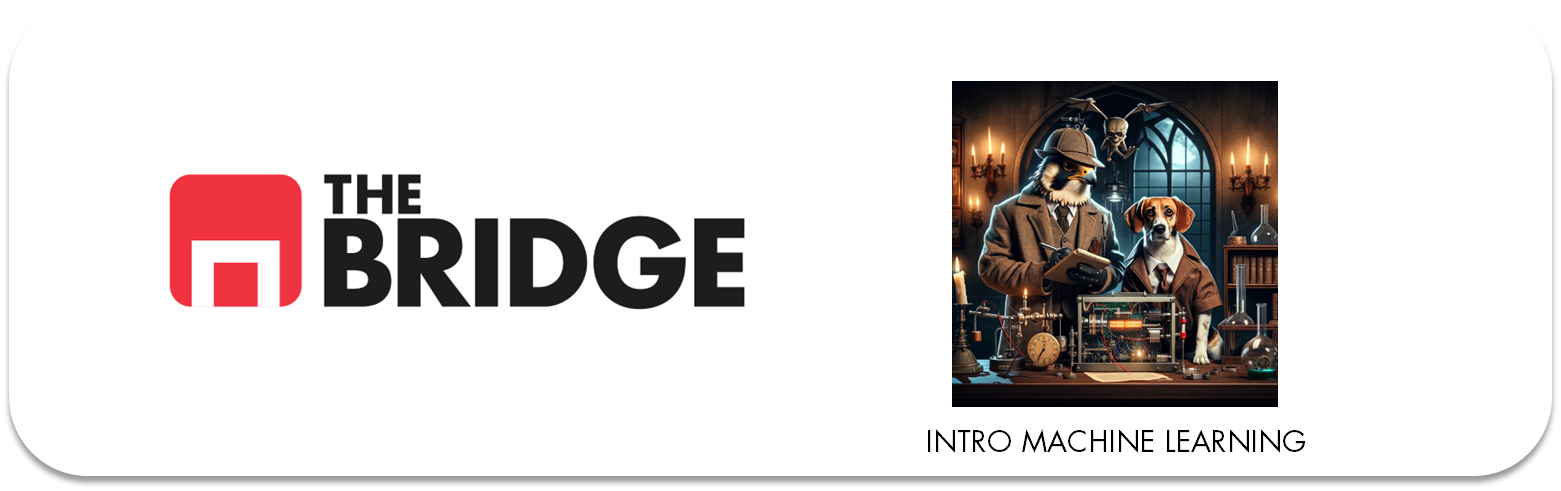

*NOTA: [Adaptado de "Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow" de Aurélien Géron]*

## ML INTRO PRÁCTICA (IV): Preparación de Features Numéricas

In [1]:
# Recuperemos lo hecho en la sesión anterior

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from bootcampviztools import plot_combined_graphs
from sklearn.model_selection import train_test_split


# Código extra para los tamaños de las fuentes y los "ticks" de los ejes, esto no lo vimos al hablar de matplotlib así que una extra
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)


df_inmo = pd.read_csv("../data/ejemplo_housing.csv")

train_set, test_set = train_test_split(df_inmo, test_size=0.2, random_state=42)

train_set["income_cat"] = pd.cut(train_set["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

train_set["rooms_per_house"] = train_set["total_rooms"] / train_set["households"]
train_set["bedrooms_ratio"] = train_set["total_bedrooms"] / train_set["total_rooms"]

features = ["ocean_proximity", "income_cat", "rooms_per_house","total_rooms","housing_median_age","bedrooms_ratio"]

target = "median_house_value"



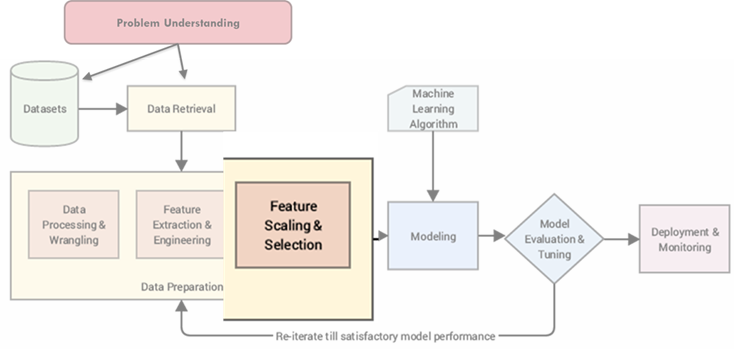

Con escasas excepciones, la mayoría de los algoritmos de machine learning para construir modelos no funcionan bien cuando las variables y features numéricas tienen escalas y rangos de valores muy diferentes. Si no "escalamos" (igualamos escalas) lo que suele pasar es que los algoritmos "pasan" de considerar las variables con menores rangos o valores más pequeños y se centran en las variables numéricas con rangos superiores.

Hay dos formas de "escalar" o asimilar los rangos: escalado min-max (*min-max scaling*) y la estandarización (*standardization*)

### 1. Min-Max Scaling

También se le conoce como normalización. Es el método más sencillo y lo que hace es transformar los rangos de las variables numéricas para que estos estén entre 0 y 1:

$$ \hat x_i = \frac{x_i - x_{min}}{x_{max} - x_{min}}$$

Aunque `MinMaxScaler` permite cambiar el rango con el argumento `feature_range`. Aquí usaremos el rango $[-1, 1]$, que en general para un rango $[a, b]$ es:

$$ \hat x_i = a + (b - a)\frac{x_i - x_{min}}{x_{max} - x_{min}}$$

In [2]:
from sklearn.preprocessing import MinMaxScaler

features_num = ["rooms_per_house","total_rooms","housing_median_age","bedrooms_ratio"]
min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
resultado_min_max = pd.DataFrame(min_max_scaler.fit_transform(train_set[features_num]), columns= features_num)
resultado_min_max

,rooms_per_house,total_rooms,housing_median_age,bedrooms_ratio
0,-0.932682,-0.859032,0.294118,-0.790101
1,-0.949105,-0.883858,-0.568627,-0.629047
2,-0.942499,-0.865493,1.000000,-0.747589
3,-0.928410,-0.948161,-0.058824,-0.645528
4,-0.958180,-0.928982,0.333333,-0.637343
...,...,...,...,...
16341,-0.936574,-0.947754,-0.098039,-0.815639
16342,-0.947496,-0.897746,0.372549,-0.665564
16343,-0.952376,-0.757338,-0.137255,-0.609901
16344,-0.948739,-0.933510,0.058824,-0.682322


In [3]:
resultado_min_max.describe()

,rooms_per_house,total_rooms,housing_median_age,bedrooms_ratio
count,16346.000000,16346.000000,16346.000000,16346.000000
mean,-0.931223,-0.865835,0.082591,-0.748855
std,0.034885,0.112708,0.494526,0.128182
min,-1.000000,-1.000000,-1.000000,-1.000000
25%,-0.946083,-0.926578,-0.333333,-0.831830
50%,-0.934000,-0.892201,0.098039,-0.770856
75%,-0.921663,-0.840578,0.411765,-0.689278
max,1.000000,1.000000,1.000000,1.000000


No igualamos todavía porque nos queda un detalle por ver sobre las distribuciones tipo *heavy-tail* (como las que hemos visto para precios, ingresos y demás en bastantes datasets)

### 2. Standardization

Hace la siguiente transformación para cada valor de una variable numérica X:

$$\hat x_i = \dfrac{x_i - \bar x}{s_x}\ \text{, donde } \bar x \text{ es la media y } s_x \text{ la desviación estándar de la variable numérica}$$

In [4]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
resultado_standardization = pd.DataFrame(std_scaler.fit_transform(train_set[features_num]),columns = features_num)
resultado_standardization.head()

,rooms_per_house,total_rooms,housing_median_age,bedrooms_ratio
0,-0.041816,0.060356,0.427749,-0.321791
1,-0.512619,-0.159918,-1.316896,0.934699
2,-0.323245,0.003031,1.855185,0.009874
3,0.080636,-0.730463,-0.285969,0.806117
4,-0.772764,-0.560292,0.507051,0.869973


In [5]:
resultado_standardization.describe()

,rooms_per_house,total_rooms,housing_median_age,bedrooms_ratio
count,1.634600e+04,1.634600e+04,1.634600e+04,1.634600e+04
mean,3.890467e-17,6.607274e-17,1.564881e-17,1.771358e-16
std,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00
min,-1.971583e+00,-1.190419e+00,-2.189218e+00,-1.959350e+00
25%,-4.259837e-01,-5.389643e-01,-8.410835e-01,-6.473450e-01
50%,-7.961065e-02,-2.339439e-01,3.123857e-02,-1.716490e-01
75%,2.740394e-01,2.240945e-01,6.656546e-01,4.647986e-01
max,5.536109e+01,1.655516e+01,1.855185e+00,1.364397e+01


En este caso lo que se busca es que la media sea 0 o casi y la desviación estándar 1 o casi. Este escalado no impone restricciones al rango y le afectan menos los outliers.

De nuevo no tocamos nada todavía... Veamos por qué:

### 3. Transformado de distribuciones

Si nos fijamos en distribuciones tipo "total_rooms":


<Axes: >

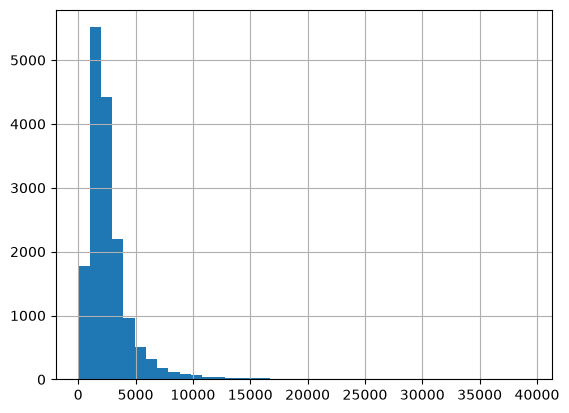

In [6]:
train_set["total_rooms"].hist(bins = 40)

Vemos ese efecto *heavy-tail* que hemos contemplado en otras distribuciones y que provoca que cuando escalemos los valores se van a concentrar en rangos muy pequeños:

In [7]:
resultado_min_max["total_rooms"].describe()

count    16346.000000
mean        -0.865835
std          0.112708
min         -1.000000
25%         -0.926578
50%         -0.892201
75%         -0.840578
max          1.000000
Name: total_rooms, dtype: float64

In [8]:
resultado_min_max.total_rooms.quantile(0.90)

np.float64(-0.7626545251055603)

Hemos concentrado el 90% de los valores entre -1 y -0.76, pero todavía quedan valores entre -0.76 y 1. Esto le sienta mal en general a los algoritmos de Machine Learning y por eso primero hacemos una transformación de las variables tipo "total_rooms":

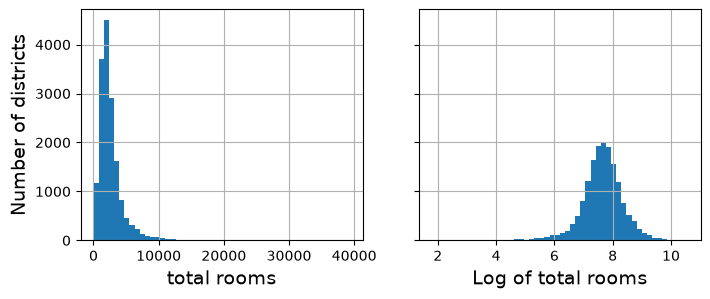

In [9]:
# Código extra: histograma de total_rooms antes y después de aplicar el logaritmo
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
train_set["total_rooms"].hist(ax=axs[0], bins=50)
train_set["total_rooms"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("total rooms")
axs[1].set_xlabel("Log of total rooms")
axs[0].set_ylabel("Number of districts")
plt.show()

Y ahora sobre la transformada aplicaríamos el min_max o el escalado:

In [10]:
train_set["log_total_room"] = train_set["total_rooms"].apply(np.log)
train_set["total_room_tr"] = min_max_scaler.fit_transform(train_set[["log_total_room"]])

<Axes: >

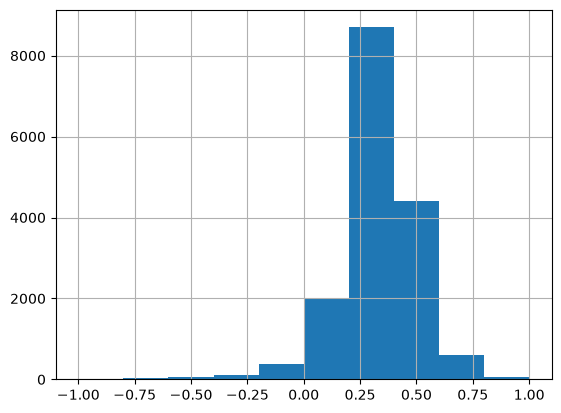

In [11]:
train_set["total_room_tr"].hist()

### 4. Aplicamos todas las transformaciones

Primero veamos si es conveniente aplicar la transformación logarítmica en alguna otra variable:

array([[<Axes: title={'center': 'rooms_per_house'}>,
        <Axes: title={'center': 'total_rooms'}>],
       [<Axes: title={'center': 'housing_median_age'}>,
        <Axes: title={'center': 'bedrooms_ratio'}>]], dtype=object)

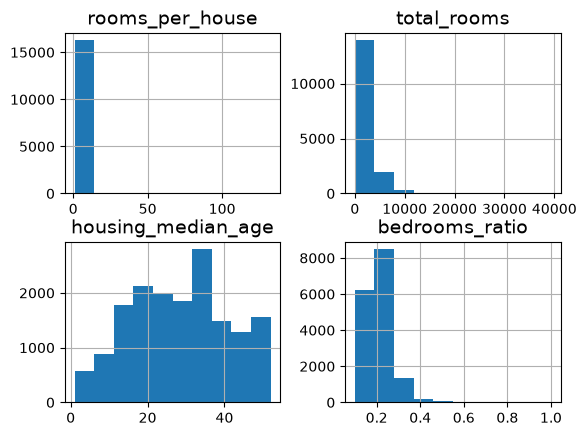

In [12]:
f_num = ["rooms_per_house","total_rooms","housing_median_age","bedrooms_ratio"]
train_set[f_num].hist()

Es necesario aplicarla a "bedrooms_ratio", lo que era de esperar porque depende de "total_rooms". Pero también observamos que hay un outlier o varios en "rooms_per_house" que deberíamos tratar: 

In [13]:
train_set.rooms_per_house.describe()

count    16346.000000
mean         5.415940
std          2.296221
min          0.888889
25%          4.437817
50%          5.233142
75%          6.045176
max        132.533333
Name: rooms_per_house, dtype: float64

(2,)


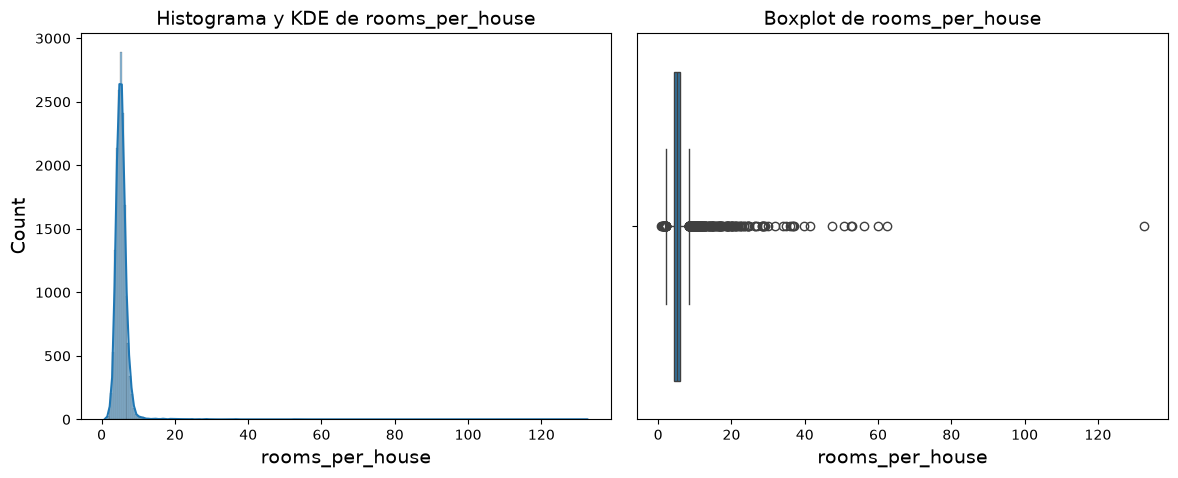

In [14]:
plot_combined_graphs(train_set, ["rooms_per_house"])

Aplicaremos la transformación a todas ellas:

In [15]:

for col in ["rooms_per_house","total_rooms","bedrooms_ratio"]:
    train_set[f"log_{col}"] = train_set[col].apply(np.log)
    train_set[col] = min_max_scaler.fit_transform(train_set[[f"log_{col}"]])

train_set["housing_median_age"] = min_max_scaler.fit_transform(train_set[["housing_median_age"]])

array([[<Axes: title={'center': 'rooms_per_house'}>,
        <Axes: title={'center': 'total_rooms'}>],
       [<Axes: title={'center': 'housing_median_age'}>,
        <Axes: title={'center': 'bedrooms_ratio'}>]], dtype=object)

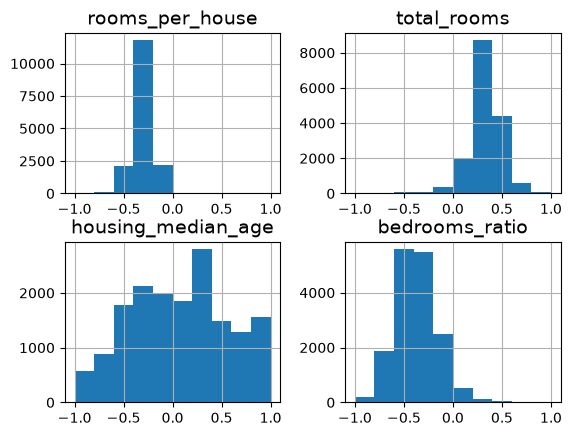

In [16]:
f_num = ["rooms_per_house","total_rooms","housing_median_age","bedrooms_ratio"]
train_set[f_num].hist()